Keeping CHL as the reconstruction target, aligns SST and BBP443 to the CHL grid/time axis, computes training-only normalization statistics, rebuilds the sample/patch indices, and saves a model-ready Zarr store plus the same metadata files used by the existing models.

In [5]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from pathlib import Path

In [6]:
# ============================================================
# 1. SETTINGS
# ============================================================

PROJECT_DIR = Path('/d/hpc/home/dn9954/MasterT/MastersThesis')
RAW_DIR = PROJECT_DIR / 'data' / 'raw_data'
OUTPUT_DIR = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHL_PATH = RAW_DIR / 'cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D_CHL_11.54E-22.79E_35.45N-45.99N_2016-06-01-2026-06-01.nc'
BBP_PATH = RAW_DIR / 'cmems_obs-oc_med_bgc-optics_my_l3-multi-1km_P1D_BBP443_11.54E-22.79E_35.45N-45.99N_2016-06-01-2026-06-01.nc'
SST_PATH = RAW_DIR / 'SST_MED_SST_L3S_NRT_OBSERVATIONS_010_012_b_multi-vars_11.55E-22.79E_35.45N-46.00N_2016-06-01-2026-06-01.nc'

CHL_VAR = 'CHL'
BBP_VAR = 'BBP443'
SST_VAR = 'adjusted_sea_surface_temperature'
SST_QUALITY_VAR = 'quality_level'

SST_MIN_QUALITY = 4

CHL_MIN = 0.01
CHL_MAX = 100.0
BBP_MIN = 1e-8
SST_MIN_C = -5.0
SST_MAX_C = 40.0

PATCH_SIZE = 128
PATCH_STRIDE = 128
MIN_OCEAN_FRACTION = 0.20
MIN_TARGET_VALID_FRACTION = 0.05
MAX_TEMPORAL_OFFSET = 3

TRAIN_START = '2016-06-01'
TRAIN_END = '2024-12-31'
VAL_START = '2025-01-01'
VAL_END = '2025-12-31'
TEST_START = '2026-01-01'
TEST_END = '2026-06-01'

print('CHL:', CHL_PATH)
print('BBP:', BBP_PATH)
print('SST:', SST_PATH)


CHL: /d/hpc/home/dn9954/MasterT/MastersThesis/data/raw_data/cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D_CHL_11.54E-22.79E_35.45N-45.99N_2016-06-01-2026-06-01.nc
BBP: /d/hpc/home/dn9954/MasterT/MastersThesis/data/raw_data/cmems_obs-oc_med_bgc-optics_my_l3-multi-1km_P1D_BBP443_11.54E-22.79E_35.45N-45.99N_2016-06-01-2026-06-01.nc
SST: /d/hpc/home/dn9954/MasterT/MastersThesis/data/raw_data/SST_MED_SST_L3S_NRT_OBSERVATIONS_010_012_b_multi-vars_11.55E-22.79E_35.45N-46.00N_2016-06-01-2026-06-01.nc


In [7]:
# ============================================================
# 2. LOAD DATASETS
# ============================================================

ds_chl = xr.open_dataset(CHL_PATH, chunks={'time': 16})
ds_bbp = xr.open_dataset(BBP_PATH, chunks={'time': 16})
ds_sst = xr.open_dataset(SST_PATH, chunks={'time': 8})

chl = ds_chl[CHL_VAR]
bbp = ds_bbp[BBP_VAR]
sst_raw = ds_sst[SST_VAR]
sst_quality_raw = ds_sst[SST_QUALITY_VAR]

print('CHL variable:', CHL_VAR)
print('BBP variable:', BBP_VAR)
print('SST variable:', SST_VAR)
print('SST quality variable:', SST_QUALITY_VAR)
print('CHL shape:', chl.shape)
print('BBP shape:', bbp.shape)
print('SST shape:', sst_raw.shape)
print('SST units:', sst_raw.attrs.get('units'))


CHL variable: CHL
BBP variable: BBP443
SST variable: adjusted_sea_surface_temperature
SST quality variable: quality_level
CHL shape: (3653, 1042, 876)
BBP shape: (3653, 1042, 876)
SST shape: (3653, 1267, 1350)
SST units: kelvin


In [8]:
# ============================================================
# 3. ALIGN BBP443 AND HIGH-RESOLUTION SST TO CHL
# ============================================================

bbp = bbp.reindex(time=chl.time)
same_bbp_lat = np.array_equal(bbp.latitude.values, chl.latitude.values)
same_bbp_lon = np.array_equal(bbp.longitude.values, chl.longitude.values)
if not (same_bbp_lat and same_bbp_lon):
    print('Regridding BBP443 to CHL grid...')
    bbp = bbp.interp(latitude=chl.latitude, longitude=chl.longitude, method='linear')

sst_raw = sst_raw.reindex(time=chl.time)
sst_quality_raw = sst_quality_raw.reindex(time=chl.time)

sst = sst_raw - 273.15
sst.attrs['units'] = 'degree_Celsius'

# Build the quality mask on the native high-resolution SST grid.
sst_valid_hr = (
    np.isfinite(sst)
    & (sst_quality_raw >= SST_MIN_QUALITY)
    & (sst >= SST_MIN_C)
    & (sst <= SST_MAX_C)
)
sst_good_hr = sst.where(sst_valid_hr)

print('Regridding high-resolution SST to CHL grid...')
sst = sst_good_hr.interp(
    latitude=chl.latitude,
    longitude=chl.longitude,
    method='linear',
)

# Quality level is categorical: nearest-neighbour only.
sst_quality = sst_quality_raw.interp(
    latitude=chl.latitude,
    longitude=chl.longitude,
    method='nearest',
)

sst_valid = (
    np.isfinite(sst)
    & (sst_quality >= SST_MIN_QUALITY)
    & (sst >= SST_MIN_C)
    & (sst <= SST_MAX_C)
)

chl_valid = np.isfinite(chl) & (chl >= CHL_MIN) & (chl <= CHL_MAX)
bbp_valid = np.isfinite(bbp) & (bbp > BBP_MIN)

print('Aligned shapes:')
print(' CHL:', chl.shape)
print(' BBP:', bbp.shape)
print(' SST:', sst.shape)
print(' SST quality:', sst_quality.shape)


Regridding high-resolution SST to CHL grid...
Aligned shapes:
 CHL: (3653, 1042, 876)
 BBP: (3653, 1042, 876)
 SST: (3653, 1042, 876)
 SST quality: (3653, 1042, 876)


In [9]:
# ============================================================
# 4. MASKS + AUXILIARY AVAILABILITY
# ============================================================

# chl_valid, bbp_valid and sst_valid were already created in the
# alignment cell. In particular, sst_valid includes quality_level >= 4.

# Ocean = pixel that contains at least one valid CHL measurement over the period.
ocean_mask = chl_valid.any(dim='time').compute()

print('Ocean pixels:', int(ocean_mask.sum()), '/', ocean_mask.size)

# How useful are the auxiliary variables specifically where CHL is missing?
chl_missing_ocean = (~chl_valid) & ocean_mask

missing_count = chl_missing_ocean.sum().compute().item()
bbp_when_chl_missing = (bbp_valid & chl_missing_ocean).sum().compute().item()
sst_when_chl_missing = (sst_valid & chl_missing_ocean).sum().compute().item()

bbp_when_chl_missing_pct = (
    100.0 * bbp_when_chl_missing / missing_count if missing_count else np.nan
)
sst_when_chl_missing_pct = (
    100.0 * sst_when_chl_missing / missing_count if missing_count else np.nan
)

print(f'CHL missing ocean pixels: {missing_count:,}')
print(f'BBP443 available where CHL missing: {bbp_when_chl_missing_pct:.3f}%')
print(f'SST available where CHL missing: {sst_when_chl_missing_pct:.3f}%')


Ocean pixels: 470147 / 912792
CHL missing ocean pixels: 762,037,966
BBP443 available where CHL missing: 0.040%
SST available where CHL missing: 40.155%


In [10]:
# ============================================================
# 5. TRAIN / VALIDATION / TEST SPLITS
# ============================================================

dates = pd.to_datetime(chl.time.values)

def indices_between(start, end):
    return np.where((dates >= pd.Timestamp(start)) & (dates <= pd.Timestamp(end)))[0]

train_indices = indices_between(TRAIN_START, TRAIN_END)
val_indices = indices_between(VAL_START, VAL_END)
test_indices = indices_between(TEST_START, TEST_END)

print("Train days:", len(train_indices), dates[train_indices[0]], "->", dates[train_indices[-1]])
print("Val days:", len(val_indices), dates[val_indices[0]], "->", dates[val_indices[-1]])
print("Test days:", len(test_indices), dates[test_indices[0]], "->", dates[test_indices[-1]])

Train days: 3136 2016-06-01 00:00:00 -> 2024-12-31 00:00:00
Val days: 365 2025-01-01 00:00:00 -> 2025-12-31 00:00:00
Test days: 152 2026-01-01 00:00:00 -> 2026-06-01 00:00:00


In [11]:
# ============================================================
# 6. TRAIN-ONLY TRANSFORMS / NORMALIZATION
# ============================================================

# CHL and BBP are positive and strongly skewed -> natural log.
chl_log = xr.where(chl_valid, np.log(chl), np.nan)
bbp_log = xr.where(bbp_valid, np.log(bbp), np.nan)

# SST remains linear in degrees Celsius.
train_chl_log = chl_log.sel(time=slice(TRAIN_START, TRAIN_END))
train_bbp_log = bbp_log.sel(time=slice(TRAIN_START, TRAIN_END))
train_sst = sst.sel(time=slice(TRAIN_START, TRAIN_END))

def mean_std(da):
    mean = float(da.mean(skipna=True).compute().item())
    std = float(da.std(skipna=True).compute().item())
    if not np.isfinite(mean) or not np.isfinite(std) or std <= 0:
        raise ValueError(f"Invalid normalization statistics: mean={mean}, std={std}")
    return mean, std

chl_mean, chl_std = mean_std(train_chl_log)
bbp_mean, bbp_std = mean_std(train_bbp_log)
sst_mean, sst_std = mean_std(train_sst)

print(f"CHL log: mean={chl_mean:.6f}, std={chl_std:.6f}")
print(f"BBP443 log: mean={bbp_mean:.6f}, std={bbp_std:.6f}")
print(f"SST C: mean={sst_mean:.6f}, std={sst_std:.6f}")

chl_norm = ((chl_log - chl_mean) / chl_std).astype("float32")
bbp_norm = ((bbp_log - bbp_mean) / bbp_std).astype("float32")
sst_norm = ((sst - sst_mean) / sst_std).astype("float32")

CHL log: mean=-2.563137, std=0.799484
BBP443 log: mean=-6.297518, std=0.597200
SST C: mean=21.494372, std=4.778851


In [12]:
# ============================================================
# 7. TEMPORAL FALLBACK ANALYSIS FOR CHL (same logic as before)
# ============================================================

# This computes masks only; it does not load all CHL values into RAM.
mask_np = chl_valid.compute().values.astype(bool)
ocean_np = ocean_mask.values.astype(bool)

rows = []
for i in range(MAX_TEMPORAL_OFFSET, len(dates) - MAX_TEMPORAL_OFFSET):
    target_missing = (~mask_np[i]) & ocean_np
    n_missing = int(target_missing.sum())
    if n_missing == 0:
        continue

    visible_1 = mask_np[i - 1] | mask_np[i + 1]
    visible_2 = visible_1 | mask_np[i - 2] | mask_np[i + 2]
    visible_3 = visible_2 | mask_np[i - 3] | mask_np[i + 3]

    rows.append({
        "date": dates[i],
        "visible_pm1_pct": 100.0 * (target_missing & visible_1).sum() / n_missing,
        "visible_pm2_pct": 100.0 * (target_missing & visible_2).sum() / n_missing,
        "visible_pm3_pct": 100.0 * (target_missing & visible_3).sum() / n_missing,
    })

fallback_df = pd.DataFrame(rows)
display(fallback_df[["visible_pm1_pct", "visible_pm2_pct", "visible_pm3_pct"]].describe())

,visible_pm1_pct,visible_pm2_pct,visible_pm3_pct
count,3647.000000,3647.000000,3647.000000
mean,66.559566,82.932477,89.181448
std,19.069731,13.180817,9.408431
min,0.879335,10.029047,22.615545
25%,54.895548,77.164289,86.204283
50%,70.225636,87.172031,92.474074
75%,81.878120,92.556771,95.596765
max,96.843842,98.436252,98.711319


In [13]:
# ============================================================
# 8. PATCH INDEX
# ============================================================

def sliding_starts(size, patch_size, stride):
    starts = list(range(0, max(size - patch_size + 1, 1), stride))
    last = max(size - patch_size, 0)
    if not starts or starts[-1] != last:
        starts.append(last)
    return sorted(set(starts))

def build_patch_index(ocean_mask_da, patch_size, min_ocean_fraction, stride=None):
    if stride is None:
        stride = patch_size

    arr = ocean_mask_da.values.astype(bool)
    h, w = arr.shape
    rows = []

    for y in sliding_starts(h, patch_size, stride):
        for x in sliding_starts(w, patch_size, stride):
            patch = arr[y:y + patch_size, x:x + patch_size]
            if patch.shape != (patch_size, patch_size):
                continue
            frac = float(patch.mean())
            if frac >= min_ocean_fraction:
                rows.append({"y": y, "x": x, "ocean_fraction": frac})

    return pd.DataFrame(rows)

patch_index = build_patch_index(
    ocean_mask, PATCH_SIZE, MIN_OCEAN_FRACTION, PATCH_STRIDE
)

display(patch_index)
print("Usable patches:", len(patch_index))
print(patch_index["ocean_fraction"].describe())

,y,x,ocean_fraction
0,0,0,0.998779
1,0,128,0.983093
2,0,256,0.994629
3,0,384,1.000000
4,0,512,1.000000
5,0,640,1.000000
6,0,748,0.979309
7,128,0,0.840698
8,128,128,0.275696
9,128,256,0.743408


Usable patches: 40
count    40.000000
mean      0.730809
std       0.280744
min       0.211243
25%       0.463333
50%       0.823822
75%       0.985977
max       1.000000
Name: ocean_fraction, dtype: float64


In [14]:
# ============================================================
# 9. SAMPLE INDEX
# ============================================================

def build_sample_index(split_name, indices, max_offset=3):
    rows = []
    split_set = set(int(i) for i in indices)

    for idx in indices:
        idx = int(idx)
        required = list(range(idx - max_offset, idx + max_offset + 1))

        if required[0] < 0 or required[-1] >= len(dates):
            continue
        if not all(j in split_set for j in required):
            continue

        actual = dates[idx - max_offset: idx + max_offset + 1]
        expected = pd.date_range(
            dates[idx] - pd.Timedelta(days=max_offset),
            dates[idx] + pd.Timedelta(days=max_offset),
            freq="D",
        )
        if not np.array_equal(actual.values, expected.values):
            continue

        for _, patch in patch_index.iterrows():
            y = int(patch.y)
            x = int(patch.x)

            ocean_patch = ocean_np[y:y + PATCH_SIZE, x:x + PATCH_SIZE]
            target_valid_patch = mask_np[idx, y:y + PATCH_SIZE, x:x + PATCH_SIZE]

            ocean_pixels = int(ocean_patch.sum())
            if ocean_pixels == 0:
                continue

            valid_target_pixels = int((target_valid_patch & ocean_patch).sum())
            target_valid_fraction = valid_target_pixels / ocean_pixels

            if target_valid_fraction < MIN_TARGET_VALID_FRACTION:
                continue

            rows.append({
                "split": split_name,
                "time_idx": idx,
                "date": dates[idx],
                "y": y,
                "x": x,
                "ocean_fraction": float(patch.ocean_fraction),
                "target_valid_pixels": valid_target_pixels,
                "target_valid_fraction": float(target_valid_fraction),
            })

    return rows

sample_rows = []
sample_rows += build_sample_index("train", train_indices, MAX_TEMPORAL_OFFSET)
sample_rows += build_sample_index("validation", val_indices, MAX_TEMPORAL_OFFSET)
sample_rows += build_sample_index("test", test_indices, MAX_TEMPORAL_OFFSET)

sample_index = pd.DataFrame(sample_rows)

print("Samples per split:")
print(sample_index.groupby("split").size())
print("\nUnique target days:")
print(sample_index.groupby("split")["date"].nunique())
print("\nTarget valid fraction:")
display(sample_index.groupby("split")["target_valid_fraction"].describe())

Samples per split:
split
test           4213
train         99368
validation    11695
dtype: int64

Unique target days:
split
test           146
train         3123
validation     359
Name: date, dtype: int64

Target valid fraction:


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,4213.0,0.656461,0.314934,0.050354,0.381306,0.761905,0.945115,1.0
train,99368.0,0.685057,0.298248,0.050032,0.452576,0.800538,0.941635,1.0
validation,11695.0,0.709964,0.293660,0.050085,0.505587,0.836398,0.953110,1.0


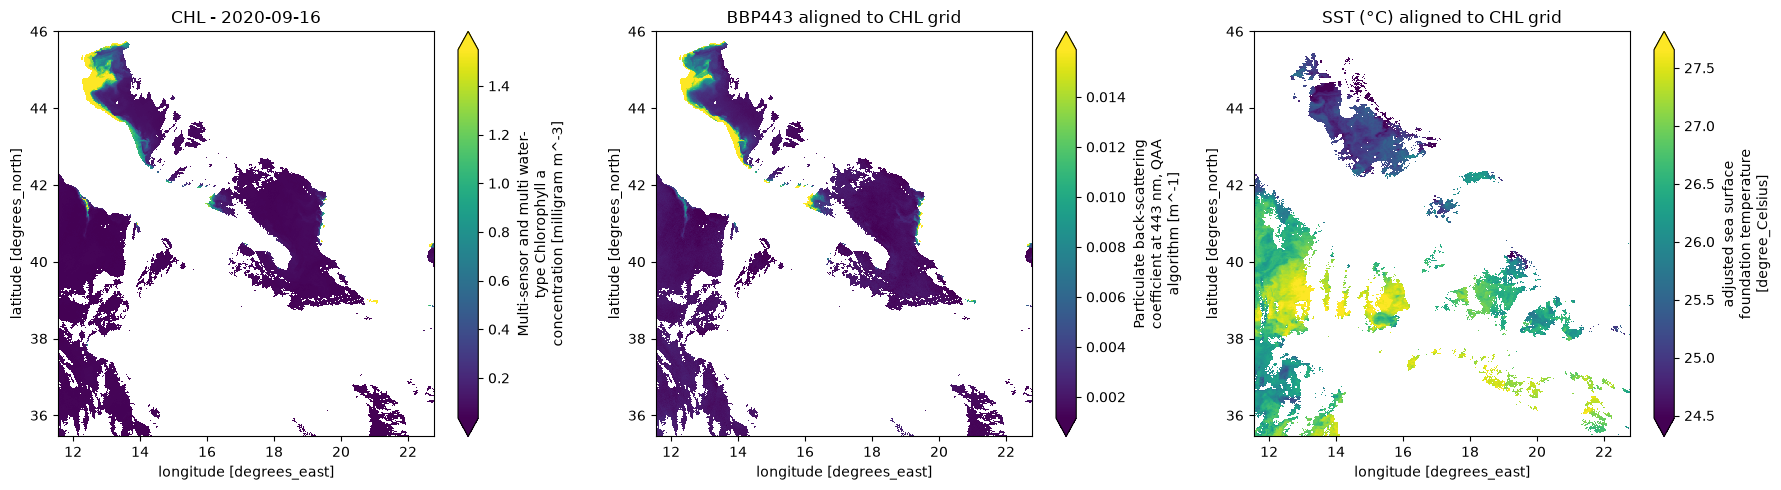

In [15]:
# ============================================================
# 10. VISUAL SANITY CHECK
# ============================================================

# Pick one date and show all three aligned inputs.
idx = int(train_indices[len(train_indices) // 2])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

chl.isel(time=idx).plot(ax=axes[0], robust=True)
axes[0].set_title(f"CHL - {dates[idx].date()}")

bbp.isel(time=idx).plot(ax=axes[1], robust=True)
axes[1].set_title("BBP443 aligned to CHL grid")

sst.isel(time=idx).plot(ax=axes[2], robust=True)
axes[2].set_title("SST (°C) aligned to CHL grid")

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# 11. SAVE PREPROCESSING METADATA
# ============================================================

# As in the original CHL-only preprocessing notebook, we do not save a
# second copy of the full gridded data. The models will read the original
# NetCDF files and use the statistics/configuration saved here.

sample_index.to_csv(OUTPUT_DIR / "sample_index.csv", index=False)
patch_index.to_csv(OUTPUT_DIR / "patch_index.csv", index=False)
ocean_mask.to_netcdf(OUTPUT_DIR / "ocean_mask.nc")
fallback_df.to_csv(OUTPUT_DIR / "temporal_fallback_analysis.csv", index=False)

normalization_df = pd.DataFrame([
    {"variable": "CHL", "transform": "natural_log", "train_mean": chl_mean, "train_std": chl_std},
    {"variable": "BBP443", "transform": "natural_log", "train_mean": bbp_mean, "train_std": bbp_std},
    {"variable": "SST", "transform": "linear_celsius", "train_mean": sst_mean, "train_std": sst_std},
])
normalization_df.to_csv(OUTPUT_DIR / "normalization.csv", index=False)

config = {
    "data_version": "chl_sst_bbp443_v1",
    # Keep raw NetCDF paths, matching the original CHL preprocessing approach.
    "data_path": str(CHL_PATH),  # backward-compatible alias for existing CHL loaders
    "chl_path": str(CHL_PATH),
    "bbp443_path": str(BBP_PATH),
    "sst_path": str(SST_PATH),
    "chl_variable": CHL_VAR,
    "bbp443_variable": BBP_VAR,
    "sst_variable": SST_VAR,
    "sst_quality_variable": SST_QUALITY_VAR,
    "sst_min_quality": int(SST_MIN_QUALITY),
    "chl_min": CHL_MIN,
    "chl_max": CHL_MAX,
    "bbp_min": BBP_MIN,
    "sst_min_c": SST_MIN_C,
    "sst_max_c": SST_MAX_C,
    "patch_size": PATCH_SIZE,
    "patch_stride": PATCH_STRIDE,
    "min_ocean_fraction": MIN_OCEAN_FRACTION,
    "min_target_valid_fraction": MIN_TARGET_VALID_FRACTION,
    "max_temporal_offset": MAX_TEMPORAL_OFFSET,
    "train_start": TRAIN_START,
    "train_end": TRAIN_END,
    "validation_start": VAL_START,
    "validation_end": VAL_END,
    "test_start": TEST_START,
    "test_end": TEST_END,
    "chl_transform": "natural_log",
    "chl_train_mean": float(chl_mean),
    "chl_train_std": float(chl_std),
    # Backward-compatible aliases used by current CHL-only loaders/evaluators.
    "transform": "natural_log",
    "normalization": "zscore_using_training_data",
    "train_mean": float(chl_mean),
    "train_std": float(chl_std),
    "bbp443_transform": "natural_log",
    "bbp443_train_mean": float(bbp_mean),
    "bbp443_train_std": float(bbp_std),
    "sst_transform": "linear_celsius",
    "sst_train_mean": float(sst_mean),
    "sst_train_std": float(sst_std),
    "bbp443_available_where_chl_missing_pct": float(bbp_when_chl_missing_pct),
    "sst_available_where_chl_missing_pct": float(sst_when_chl_missing_pct),
    # Tell future loaders that auxiliaries must be aligned to the CHL grid.
    "aux_alignment_reference": "CHL",
    "aux_time_alignment": "reindex_to_chl_time",
    "aux_spatial_alignment": "linear_interp_to_chl_lat_lon_if_needed",
}

with open(OUTPUT_DIR / "preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("\nSaved preprocessing files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)



Saved preprocessing files:
 - normalization.csv
 - ocean_mask.nc
 - patch_index.csv
 - preprocessing_config.json
 - sample_index.csv
 - temporal_fallback_analysis.csv


In [17]:
# ============================================================
# 12. FINAL VALIDATION
# ============================================================

assert chl.shape == bbp.shape == sst.shape == sst_quality.shape
assert np.array_equal(chl.time.values, bbp.time.values)
assert np.array_equal(chl.time.values, sst.time.values)
assert np.array_equal(chl.latitude.values, bbp.latitude.values)
assert np.array_equal(chl.latitude.values, sst.latitude.values)
assert np.array_equal(chl.longitude.values, bbp.longitude.values)
assert np.array_equal(chl.longitude.values, sst.longitude.values)

required_files = [
    'sample_index.csv',
    'patch_index.csv',
    'normalization.csv',
    'ocean_mask.nc',
    'temporal_fallback_analysis.csv',
    'preprocessing_config.json',
]

for name in required_files:
    path = OUTPUT_DIR / name
    assert path.exists(), f'Missing preprocessing output: {path}'

print('\nPreprocessing completed successfully.')
print('High-resolution SST was quality-filtered and aligned to the CHL grid.')
print('No Zarr/model-data copy was created.')
print('Models should read the NetCDF files listed in preprocessing_config.json.')
print('\nSamples:')
print(sample_index.groupby('split').size())



Preprocessing completed successfully.
High-resolution SST was quality-filtered and aligned to the CHL grid.
No Zarr/model-data copy was created.
Models should read the NetCDF files listed in preprocessing_config.json.

Samples:
split
test           4213
train         99368
validation    11695
dtype: int64
